<a href="https://colab.research.google.com/github/alanJoshiGeorge/ai-ml-lab/blob/main/experiment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "insurance.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "mirichoi0218/insurance",
  file_path
)

print("First 5 records:", df.head())

/tmp/ipykernel_996/253407329.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'insurance' dataset.
First 5 records:    age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler


print(df.info())
print(df.isnull().sum())

X = df.drop("charges", axis=1)
y = df["charges"]

categorical_features = ["sex", "smoker", "region"]
numerical_features = ["age", "bmi", "children"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(drop="first"), categorical_features),
    ]
)

# Split data into training and testing sets BEFORE scaling to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Fit preprocessor on training data and transform both train and test sets
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Train Linear Regression model directly
regressor = LinearRegression()
regressor.fit(X_train_scaled, y_train)

# Make predictions on test set
y_pred = regressor.predict(X_test_scaled)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance:")
print("------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

# Test prediction with a sample person
sample = pd.DataFrame(
    {
        "age": [35],
        "sex": ["male"],
        "bmi": [28.5],
        "children": [2],
        "smoker": ["no"],
        "region": ["southeast"],
    }
)

# Transform the sample using the fitted preprocessor
sample_scaled = preprocessor.transform(sample)
prediction = regressor.predict(sample_scaled)

print("\nPredicted Insurance Charge:")
print(f"${prediction[0]:.2f}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Model Performance:
------------------
Mean Absolute Error (MAE): 4181.19
Mean Squared Error (MSE): 33596915.85
Root Mean Squared Error (RMSE): 5796.28
R² Score: 0.7836

Predicted Insurance Charge:
$6844.17


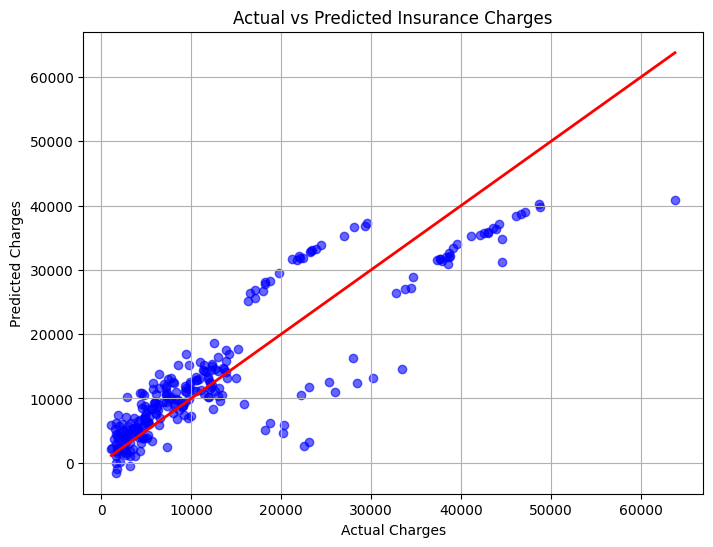

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, color="blue", alpha=0.6)

# Perfect prediction line
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linewidth=2)

plt.title("Actual vs Predicted Insurance Charges")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.grid(True)
plt.show()

Slope: 2.0139325932693506
Intercept: 3.2579388659568593
R² Score: 0.976455254882662


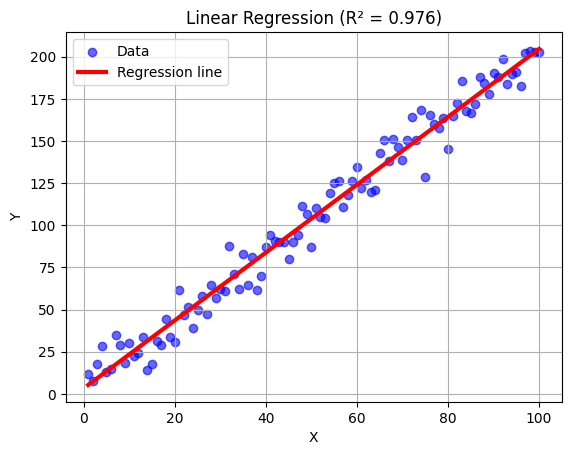

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Generate data
np.random.seed(42)

X = np.linspace(1, 100, 100).reshape(-1, 1)

# y = 2x + 5 + noise
noise = np.random.normal(0, 10, size=100)
y = 2 * X.flatten() + 5 + noise

# Train model
model = LinearRegression()
model.fit(X, y)

# Predictions
y_pred = model.predict(X)

# Calculate R2 score
r2 = r2_score(y, y_pred)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("R² Score:", r2)

# Plot
plt.scatter(X, y, color="blue", alpha=0.6, label="Data")
plt.plot(X, y_pred, color="red", linewidth=3, label="Regression line")
plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Linear Regression (R² = {r2:.3f})")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#Uniform cost search
import heapq

def uniform_cost_search(graph, start, goal):
    # Priority queue: (cost, node, path)
    pq = [(0, start, [])]

    visited = set()

    while pq:
        cost, node, path = heapq.heappop(pq)

        if node in visited:
            continue

        visited.add(node)
        path = path + [node]

        if node == goal:
            return path, cost

        for neighbor, edge_cost in graph[node]:
            if neighbor not in visited:
                heapq.heappush(
                    pq,
                    (cost + edge_cost, neighbor, path)
                )

    return None, float("inf")

graph = {
    'A': [('B', 2), ('C', 5)],
    'B': [('D', 4), ('E', 1)],
    'C': [('G', 2)],
    'D': [('G', 3)],
    'E': [('G', 5)],
    'G': []
}

path, cost = uniform_cost_search(graph, 'A', 'G')

print("Path:", path)
print("Cost:", cost)

Path: ['A', 'C', 'G']
Cost: 7


In [ ]:
import heapq

def a_star(graph, start, goal, heuristic):
    open_list = []
    heapq.heappush(open_list, (0, start))

    g_cost = {start: 0}
    parent = {start: None}

    while open_list:
        _, current = heapq.heappop(open_list)

        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            path.reverse()
            return path, g_cost[goal]

        for neighbor, cost in graph[current]:
            new_g = g_cost[current] + cost

            if neighbor not in g_cost or new_g < g_cost[neighbor]:
                g_cost[neighbor] = new_g
                f = new_g + heuristic[neighbor]
                heapq.heappush(open_list, (f, neighbor))
                parent[neighbor] = current

    return None, float('inf')

graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3)],
    'D': [('G', 3)],
    'E': [('G', 2)],
    'F': [('G', 2)],
    'G': []
}

heuristic = {
    'A': 7,
    'B': 6,
    'C': 4,
    'D': 2,
    'E': 1,
    'F': 2,
    'G': 0
}

path, cost = a_star(graph, 'A', 'G', heuristic)

print("Shortest Path:", " -> ".join(path))
print("Total Cost:", cost)


Shortest Path: A -> B -> D -> G
Total Cost: 6


In [ ]:
import heapq

def best_first_search(graph, heuristic, start, goal):
    priority_queue = [(heuristic[start], start)]
    visited = set()
    parent = {start: None}

    while priority_queue:
        _, current = heapq.heappop(priority_queue)

        if current in visited:
            continue

        visited.add(current)

        # Goal found
        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            return path[::-1]

        for neighbor in graph[current]:
            if neighbor not in visited:
                parent[neighbor] = current
                heapq.heappush(
                    priority_queue,
                    (heuristic[neighbor], neighbor)
                )

    return None

graph = {
    'A': ['B', 'C'],
    'B': ['D'],
    'C': ['G'],
    'D': [],
    'G': []
}

heuristic = {
    'A': 6,
    'B': 4,
    'C': 2,
    'D': 5,
    'G': 0
}

start = 'A'
goal = 'G'

path = best_first_search(graph, heuristic, start, goal)

print("Path:", path)

Path: ['A', 'C', 'G']


In [ ]:
from collections import deque

def bfs(graph, start, goal):
    queue = deque([start])
    visited = set()
    parent = {start: None}

    while queue:
        current = queue.popleft()

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            return path[::-1]

        for neighbor in graph[current]:
            if neighbor not in visited:
                parent[neighbor] = current
                queue.append(neighbor)

    return None


graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': [],
    'F': ['G'],
    'G': []
}

print("BFS:", bfs(graph, 'A', 'G'))

BFS: ['A', 'C', 'F', 'G']


In [ ]:
def dfs(graph, start, goal):
    stack = [start]
    visited = set()
    parent = {start: None}

    while stack:
        current = stack.pop()

        if current in visited:
            continue

        visited.add(current)

        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            return path[::-1]

        for neighbor in graph[current]:
            if neighbor not in visited:
                parent[neighbor] = current
                stack.append(neighbor)

    return None


print("DFS:", dfs(graph, 'A', 'G'))

DFS: ['A', 'C', 'F', 'G']


In [ ]:
[1,2,3,4,4]